In [1]:
import os
import pickle
import numpy as np
import tensorflow as tf
import pandas as pd
import tensorflow_probability as tfp
from tensorflow.keras import datasets, layers, models
import random

from skimage.morphology import skeletonize, thin

from sklearn.model_selection import train_test_split


In [35]:
root = """data\\"""
img_size = (128, 128)
chars = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C',
       'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P',
       'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c',
       'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p',
       'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
learning_rate = 10

In [3]:
src = pd.read_csv("data\english.csv")
# src.head()

In [4]:
def load_img(name):
    loc = root + name.rstrip()
    img = tf.keras.preprocessing.image.load_img(loc, target_size=img_size, color_mode="grayscale")
    img = tf.convert_to_tensor(img, dtype=tf.float32) / 255.0
    img = 1 - img
    return img

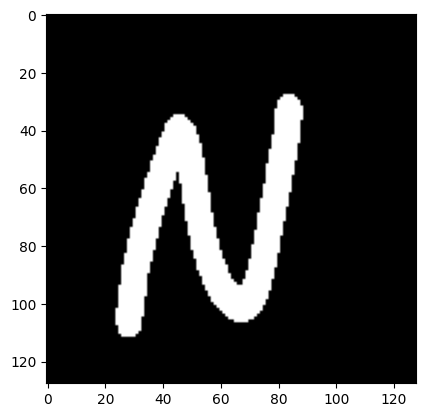

In [5]:
import matplotlib.pyplot as plt

img = load_img("Img/img024-001.png	")
plt.imshow(img, cmap='gray', vmin=0, vmax=1)

Make the image blurry

In [6]:
def randomise(image: tf.Tensor):
    random_values = tf.random.uniform(shape=(8,8,1), minval=0.1, maxval=0.9)
    random_values = tf.reshape(tf.image.resize(random_values, img_size, method="bilinear"), img_size)
    mask = tf.math.greater(image, 0.8)
    return tf.where(mask, random_values, image)

In [7]:
def skeleton(blur):
    sk = thin(blur.numpy(), 1)

    skeletons = [blur, tf.constant(sk, dtype=tf.float32)]

    for j in range(4):
        sk = thin(sk, 1)
        skeletons.append(tf.constant(sk, dtype=tf.float32))

    # Average it out; enh = enhanced
    enh = tf.add_n(skeletons) / len(skeletons)
    return enh

In [8]:
def gaussian_kernel(size: int, mean: float, std: float):
    """Generates a Gaussian kernel to be used for blurring"""
    d = tfp.distributions.Normal(mean, std)
    vals = d.prob(tf.range(start=-size, limit=size+1, dtype=tf.float32))
    gauss_kernel = tf.einsum('i,j->ij', vals, vals)
    gauss_kernel = gauss_kernel / tf.reduce_sum(gauss_kernel)  # Normalize the kernel
    return gauss_kernel[:, :, tf.newaxis, tf.newaxis]

def apply_gaussian_blur(image: tf.Tensor, kernel_size: int, sigma: float):
    kernel = gaussian_kernel(kernel_size, 0., sigma)
    kernel = tf.tile(kernel, [1, 1, image.shape[-1], 1])  # Adjust the kernel to work for each image channel
    image = tf.expand_dims(image, axis=0)  # Add a batch dimension for convolution
    blurred_image = tf.nn.depthwise_conv2d(image, kernel, strides=[1, 1, 1, 1], padding='SAME')
    return tf.squeeze(blurred_image, axis=0)  # Remove the batch dimension

def blur(img):
    blur = tf.reshape(img, [128, 128, 1])
    blur = apply_gaussian_blur(blur, 3, 1.5)
    return tf.reshape(blur, img_size)

In [9]:
def noise(image: tf.Tensor, num_groups: int = 10):
    # Detect black regions (0 value pixels)
    black_pixels = tf.where(image == 0)

    # Randomly select positions to add white pixel groups
    for _ in range(num_groups):
        if len(black_pixels) == 0:
            break  # If no more black pixels are available, stop
        
        # Randomly choose a black pixel location
        random_idx = random.randint(0, len(black_pixels) - 1)
        x, y = black_pixels[random_idx]

        x_d = random.randint(2,4)
        y_d = random.randint(2,4)

        # Define the area to replace with white pixels (within bounds)
        x_start = max(0, x - x_d // 2)
        y_start = max(0, y - y_d // 2)
        x_end = min(image.shape[0], x_start + x_d)
        y_end = min(image.shape[1], y_start + y_d)

        x_d = x_end - x_start
        y_d = y_end - y_start

        # Add white pixels to the selected region
        image = tf.tensor_scatter_nd_update(
            image, 
            indices=tf.convert_to_tensor([[i, j] for i in range(x_start, x_end) for j in range(y_start, y_end)]),
            updates=tf.random.uniform([(x_d * y_d)], minval=0.1, maxval=1.0, dtype=tf.float32)
        )
    
    return image

In [10]:
final = tf.reshape(noise(skeleton(randomise(blur(img)))), [img_size[0], img_size[1],1])

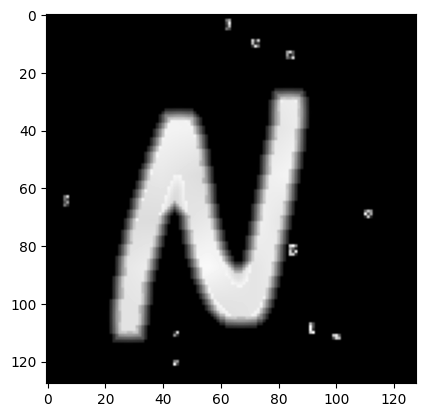

In [11]:
plt.imshow(final, cmap='gray', vmin=0, vmax=1)

---------

In [ ]:
imgs = []
labels = []

for i in range(len(src)):
    x = load_img(src.iloc[i]['image'])
    x = tf.reshape(noise(skeleton(randomise(blur(x)))), [1,img_size[0], img_size[1],1])
    imgs.append(x)

    y = src.iloc[i]['label']
    labels.append(chars.index(y))

    # plt.imshow(x, cmap='gray', vmin=0, vmax=1)

    # print(y)

In [13]:
x_train, x_test, y_train, y_test = train_test_split(imgs, labels, test_size=0.1, random_state=2)

In [14]:
x_train = tf.concat(x_train, 0)
x_test = tf.concat(x_test, 0)
y_train = tf.constant(y_train, dtype=tf.int16)
y_test = tf.constant(y_test, dtype=tf.int16)

In [15]:
datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

datagen.fit(x_train)

In [30]:
x = datagen.flow(x_train, y_train, batch_size=32)
x.next()[1]

array([ 6,  5, 10,  1, 12, 12, 12, 11,  6,  5, 10,  0,  0,  8,  5,  1,  0,
       12,  7,  5,  5,  0,  4,  7,  7,  7,  0,  7,  8, 10,  3,  6],
      dtype=int16)

In [36]:
model = models.Sequential()

# Here's the convnet
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 1)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((4, 4)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
# This is the dense net that parses the output from the convnet
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(len(chars)))

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 126, 126, 32)      320       
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 63, 63, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 15, 15, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 13, 13, 64)        36928     
                                                                 
 flatten_1 (Flatten)         (None, 10816)            

In [37]:
# This is to load the weights from the checkpoints

# # This code is always to be commented
# checkpoint = tf.train.Checkpoint(model)
# checkpoint.restore(os.getcwd() + "/Checkpoints/" + "PNN").expect_partial()

In [38]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

# Create the training data
data_gen = datagen.flow(x_train, y_train, batch_size=32)

train_data = []
train_label = []

for i in range(100):
    temp = next(data_gen)
    train_data.append(temp[0])
    train_label.append(temp[1])

train_data = tf.concat(train_data, 0)
train_label = tf.concat(train_label, 0)
# End of training data creation

# The below is how you are to apply the data augumentation method:
# Train the model with data augmentation
history = model.fit(
    train_data,
    train_label,
    epochs=5,
    validation_data=(x_test, y_test),
) # Tune these parameters later

Epoch 1/5

100/100 [==============================] - 17s 153ms/step - loss: 9.9416 - accuracy: 0.0759 - val_loss: 8.2415 - val_accuracy: 0.0833
Epoch 2/5
100/100 [==============================] - 15s 148ms/step - loss: 9.9340 - accuracy: 0.0766 - val_loss: 8.2415 - val_accuracy: 0.0833
Epoch 3/5
100/100 [==============================] - 19s 192ms/step - loss: 9.9340 - accuracy: 0.0766 - val_loss: 8.2415 - val_accuracy: 0.0833
Epoch 4/5
100/100 [==============================] - 22s 223ms/step - loss: 9.9340 - accuracy: 0.0766 - val_loss: 8.2415 - val_accuracy: 0.0833
Epoch 5/5
100/100 [==============================] - 24s 237ms/step - loss: 9.9340 - accuracy: 0.0766 - val_loss: 8.2415 - val_accuracy: 0.0833


In [24]:
# This is to save weights
# model.save_weights(os.getcwd() + "/Checkpoints/" + "PNN")

tf.Tensor(
[-1.35044006e+12 -1.20029407e+12 -1.25701063e+12 -1.16696705e+12
 -1.29453471e+12  1.22000007e+11 -1.33903588e+12 -1.31670173e+12
 -1.16992324e+12 -1.33273000e+12  1.32386005e+11 -2.79504819e+09
 -1.22597697e+12  2.99707146e+10 -1.27570870e+12 -1.15582645e+12
 -1.26759639e+12 -1.34462623e+12 -1.22552241e+12 -1.25542125e+12
 -1.28324443e+12 -1.30955189e+12 -1.03368340e+12 -4.66640634e+11
 -1.33417022e+12 -1.21877312e+12  1.44900960e+07 -1.34018908e+11
 -1.05546016e+12 -1.33895016e+12 -8.72920383e+11 -1.34474721e+12
 -1.29530056e+12 -1.34587207e+12 -3.74102000e+11 -1.53834390e+11
 -1.94493039e+11 -5.34853353e+11 -1.33923563e+12 -1.11305005e+12
 -3.98955282e+11 -1.33354383e+12 -1.31422932e+12 -1.32739957e+12
 -1.32297903e+12 -1.34001748e+12 -1.03904281e+12 -1.24885454e+12
 -1.25662934e+12 -1.31831903e+12 -1.25754461e+12 -1.34269475e+12
 -1.22653744e+12 -1.24791895e+12 -9.83787504e+11 -1.04635367e+12
  1.28773407e+11 -1.30097060e+12 -1.23671295e+12 -1.04361722e+11
 -1.26867590e+

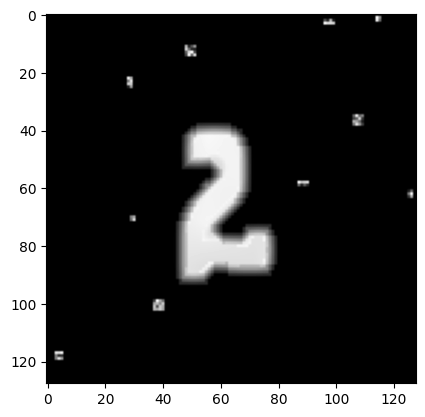

In [34]:
i = 57

y = model(tf.reshape(x_test[i], [1,128,128,1]))
print(y[0])
print(chars[tf.argmax(y[0])])

print()
plt.imshow(x_test[i], cmap='gray', vmin=0, vmax=1)

Trainsition probabilities

In [23]:
loc = "data//" + "Articles.bin" # To train more change the Articles.bin file by swapping it with freshly generated articles. Use the generator in diplomacy software.

with open(loc, "rb") as f:
    articles = pickle.load(f)

In [140]:
df2 = pd.read_csv('data//TransitionModel.csv', header=None) # read data from the csv file

In [141]:
words = []

for key in articles.values():
    text = key.replace('\n', ' ')
    split_text = text.split()
    words += split_text

In [142]:
# Update the values in the dataframe based on words

for w in words:
    for c in range(len(w) - 1):
        try:
            prev = chars.index(w[c])
            next = chars.index(w[c + 1])
            df2.loc[prev, next] += 1
        except ValueError:
            pass

In [143]:
df2.to_csv('data//TransitionModel.csv', index=False, header=False) # store data into the csv file
del df2

In [144]:
def GetProbs(prev): # The input is the index of the character, not the character itself

    df2 = pd.read_csv('data//TransitionModel.csv', header=None)

    sum = df2.loc[prev].sum()

    return df2.loc[prev].tolist() / sum

In [148]:
len(GetProbs(5))

62

In [155]:
a = tf.constant(GetProbs(5))
b = tf.constant(GetProbs(6))

tf.math.multiply(a,b)

<tf.Tensor: shape=(62,), dtype=float64, numpy=
array([1.94503794e-01, 2.83651367e-03, 1.98924335e-03, 2.83651367e-03,
       2.35762175e-03, 2.21027039e-03, 9.20945996e-04, 6.63081117e-04,
       1.47351359e-04, 4.42054078e-04, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       1.47351359e-04, 3.68378398e-05, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.47351359e-04,
       0.00000000e+00, 0.00000